# ShopSphere — LightGBM Baseline (Egus)
**IT2226 AI Innovation and Deep Learning Project** · Egus Lee's individual PR1 supervised model: a non-deep-learning baseline, with its folds and out-of-fold predictions saved so any other model can be compared against it on identical customers.

*Built with AI assistance (Claude). What was asked for, what was checked and what was changed is recorded in `ai_use_log_egus.md`.*

**Task.** Predict which customers make at least one purchase between 1 and 30 Oct 2024 (`target = 1`), using only data dated on or before the 30 Sep 2024 snapshot.

**Why a baseline.** Brief §6 requirement 1: the deep learning model must be *"evaluated properly and compared fairly against at least one non-deep-learning baseline"*. This notebook is one such baseline, together with the evaluation setup it uses: folds, metrics and comparison rankers.

**Primary metric.** Precision@k: of the *k* customers the model ranks highest (the list the CRM team can afford to contact), the share who actually bought. ROC-AUC and PR-AUC are reported alongside.

### Origin and differences from `02_lightgbm_training_pipeline.ipynb`
The feature extraction in section 3 is adapted from the team's `02_lightgbm_training_pipeline.ipynb` (author: *[teammate's name]*). This notebook differs from it in the ways below. Each difference was tested on `shopsphere.db`; the evidence is in section 2 and in the AI Use Log.

| # | In 02 | Here | Evidence |
|---|---|---|---|
| 1 | `late_deliveries_count` filtered `delivery_status = 'Late'`, a value that does not exist, so the feature was 0 for everyone | Late = `delay_days >= 1` (shared team definition, audit B1) | 0 rows have status `Late`; 81,377 shipments have `delay_days >= 1` |
| 2 | `total_pages_viewed` included 71,958 sessions median-filled with 6.0 | Only real values summed; count of filled sessions added as its own feature | Audit A1, still unfixed in the DB |
| 3 | `scale_pos_weight` inflated every probability and hurt ranking | Removed | P@1000 0.846 with vs 0.872 without; mean prediction 0.335 vs true 0.146 |
| 4 | Early stopping watched AUC **and** logloss, so training stopped at 17–19 trees | Early stop on `binary_logloss` only | 150–220 trees; P@1000 0.754 → 0.875 |
| 5 | `subsample` set without `subsample_freq`, so bagging was off | `bagging_freq = 1`, both tuned by Optuna | Identical predictions with or without `subsample` in 02 |
| 6 | No precision@k and no comparison rankers | Precision@1000 / @2500, lift, budget-derived k, and random / recency / loyalty / tier rankers | Project primary metric |
| 7 | F1-tuned 0.38 threshold | Removed: the list size comes from the budget (top-k), not a score cutoff | W3: list must stay within each country's budget |
| 8 | Gain importance presented as "most predictive" | SHAP (LightGBM's built-in `pred_contrib`) | Gain ranked pure-noise columns 15th–24th in the 126-feature baseline |
| 9 | Cell 15 gave offer advice with no policy checks and used only the last fold's model | `score_customer()` returns probability, rank and reasons only; offers belong to the Targeting and Compliance agents | `retention_offer_policy.md` §2 |
| 10 | Folds and predictions not saved | `outputs/folds.csv` and per-seed OOF predictions saved | Lets PR1 models be compared on identical customers |
| 11 | Single run | Optuna tuning (30 trials), then 5 seeds reported as mean ± sd | Guidebook PR1 rubric: "evidence of optimisations" |

### How to run
Put `shopsphere.db` next to this notebook (or set `DB_PATH`) and use **Restart & Run All**. A full run takes about 20 minutes on a laptop CPU, mostly the Optuna search. Set `RUN_TUNING = False` to reuse `outputs/best_params.json`.

## 1. Setup

In [1]:
# Pinned so results reproduce. Other packages (pandas, numpy, scikit-learn, matplotlib) use the environment's versions, printed below.
%pip install -q lightgbm==4.7.0 optuna==5.0.0

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, time, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

# ---- Configuration -------------------------------------------------------
DB_PATH     = os.environ.get('SHOPSPHERE_DB', 'shopsphere.db')
OUT_DIR     = 'outputs'
SNAPSHOT    = '2024-09-30'      # data cutoff; nothing after this date may be used
N_FOLDS     = 5
FOLD_SEED   = 42                # fixes the split; saved to outputs/folds.csv for like-for-like comparisons
SEEDS       = [1, 2, 3, 4, 5]   # model seeds for the final reported numbers
K_LIST      = [1000, 2500]      # fixed list sizes for the headline precision@k
RUN_TUNING  = True              # False = reuse outputs/best_params.json
N_TRIALS    = 30
os.makedirs(OUT_DIR, exist_ok=True)

# On Colab, upload the database if it is not already there.
if not os.path.exists(DB_PATH):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'{DB_PATH} not found. Put shopsphere.db next to this notebook or set SHOPSPHERE_DB.')

# Read-only connection: this notebook can never change the database.
conn = sqlite3.connect(f'file:{DB_PATH}?mode=ro', uri=True)
q = lambda sql: pd.read_sql_query(sql, conn)

print(f'Database: {DB_PATH} ({os.path.getsize(DB_PATH) / 1e6:.0f} MB)')
print('lightgbm', lgb.__version__, '| optuna', optuna.__version__, '| scikit-learn', sklearn.__version__,
      '| pandas', pd.__version__, '| numpy', np.__version__)

Database: shopsphere.db (258 MB)
lightgbm 4.7.0 | optuna 5.0.0 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data checks: the snapshot rule
Project rule: *no feature may use data dated after 30 Sep 2024.* These checks prove the tables this notebook uses obey it. They are `assert`s, so the notebook stops if the data ever changes.

**Plans vs results.** A date after 30 Sep is acceptable when the value was *written down* on or before 30 Sep (a promised delivery date set at checkout, a planned campaign). It is not acceptable when the value *records something that happened later* (a delivery outcome, a purchase).

In [3]:
checks = {}

# (a) Every behaviour table ends on the snapshot date.
ends = q(f'''
SELECT 'transactions'      AS tbl, MAX(transaction_timestamp) AS last_date FROM transactions UNION ALL
SELECT 'sessions',               MAX(session_timestamp)            FROM sessions        UNION ALL
SELECT 'support_tickets',        MAX(created_date)                 FROM support_tickets UNION ALL
SELECT 'retention contacts',     MAX(contact_date)                 FROM retention_contact_history UNION ALL
SELECT 'retention redemptions',  MAX(redemption_date)              FROM retention_contact_history UNION ALL
SELECT 'deliveries (delivered)', MAX(delivered_date)               FROM deliveries
''')
display(ends)
assert (ends.last_date <= SNAPSHOT).all(), 'A behaviour table has rows after the snapshot'

# (b) Delivery statuses. The 02 notebook filtered 'Late', which does not exist.
status = q('SELECT delivery_status, COUNT(*) AS n FROM deliveries GROUP BY 1 ORDER BY 2 DESC')
display(status)
late = q('SELECT SUM(delivery_status = \'Late\') AS status_Late, SUM(delay_days >= 1) AS delay_ge_1 FROM deliveries')
display(late)
checks['late_shipments_delay_ge_1'] = int(late.delay_ge_1[0])

# (c) Retention outcome flags: does any late-September flag depend on an October purchase?
#     A flag of 1 with no purchase between the contact and 30 Sep could only come from October.
ret = q(f'''
WITH c AS (
  SELECT r.*, EXISTS (SELECT 1 FROM transactions t
                      WHERE t.customer_id = r.customer_id
                        AND t.transaction_timestamp BETWEEN r.contact_date AND '{SNAPSHOT}') AS bought_by_cutoff
  FROM retention_contact_history r WHERE r.contact_date > DATE('{SNAPSHOT}', '-14 days'))
SELECT COUNT(*) AS contacts_last_14d, SUM(purchased_within_14d) AS flagged,
       SUM(purchased_within_14d = 1 AND bought_by_cutoff = 0) AS flag_needs_october
FROM c''')
display(ret)
assert ret.flag_needs_october[0] == 0, 'purchased_within_14d uses October purchases: restrict it'

# (d) Fields that legitimately run past the snapshot (plans, set on or before 30 Sep).
post = q(f'''
SELECT 'deliveries.ship_date' AS field, SUM(ship_date > '{SNAPSHOT}') AS rows_after, MAX(ship_date) AS latest FROM deliveries UNION ALL
SELECT 'deliveries.promised_date', SUM(promised_date > '{SNAPSHOT}'), MAX(promised_date) FROM deliveries UNION ALL
SELECT 'deliveries.delivered_date', SUM(delivered_date > '{SNAPSHOT}'), MAX(delivered_date) FROM deliveries''')
display(post)
assert post.set_index('field').loc['deliveries.delivered_date', 'rows_after'] == 0, 'Delivery outcomes after the snapshot: mask them'

# (e) Pages viewed: median-filled values still present (audit A1).
pv = q('SELECT SUM(pages_viewed_is_missing) AS filled, SUM(pages_viewed_is_missing = 1 AND pages_viewed = 6.0) AS filled_with_6 FROM sessions')
display(pv)
checks.update({'pages_viewed_filled': int(pv.filled[0]), 'retention_flags_needing_october': int(ret.flag_needs_october[0])})

,tbl,last_date
0,transactions,2024-09-30
1,sessions,2024-09-30
2,support_tickets,2024-09-30
3,retention contacts,2024-09-30
4,retention redemptions,2024-09-30
5,deliveries (delivered),2024-09-30


,delivery_status,n
0,Delivered,260124
1,Delivered Late,26799
2,Returned,9400
3,In Transit,3222
4,Lost,1698


,status_Late,delay_ge_1
0,0,81377


,contacts_last_14d,flagged,flag_needs_october
0,1419,91,0


,field,rows_after,latest
0,deliveries.ship_date,470,2024-10-01
1,deliveries.promised_date,2960,2024-10-07
2,deliveries.delivered_date,0,2024-09-30


,filled,filled_with_6
0,71958,71958


**What the checks show**

- **Behaviour tables** all end on 30 Sep 2024, so there is no October activity anywhere.
- **Delivery status `Late`** does not exist. Late is defined as `delay_days >= 1`, the team definition (audit B1, shipping policy §2.1: arrives "after the promised date").
- **`purchased_within_14d`** never depends on an October purchase. The data counted the 14 days only up to 30 Sep. The feature is kept, with one caveat: for contacts in the last two weeks of September the flag covers fewer than 14 days, so it means "bought between the contact and 30 Sep".
- **Dates after 30 Sep that are acceptable** (audit B3). Neither is used as a feature.
  - `ship_date` (470 rows, up to 1 Oct): dispatch is the day after payment.
  - `promised_date` (2,960 rows, up to 7 Oct): set at checkout.
- **`delivered_date`** never falls after 30 Sep. Shipments still open on that day show as `In Transit` or `Lost`, which is what the system showed at the snapshot, so nothing needs masking.
- **`pages_viewed`**: 71,958 values are the median fill 6.0, so they are excluded from page totals.

## 3. Feature extraction
One row per customer, built inside SQLite: child tables are aggregated to `customer_id` before joining, so rows never multiply.

| Group | Source tables | Examples |
|---|---|---|
| Profile | `customers` | age, tier, credit limit, loyalty score, email open rate, account age |
| Consent | `customer_preferences` | email/SMS opt-in, do-not-contact, preferred channel |
| Orders | `transactions` | order count, spend, average and maximum order value, discounts, orders in last 30/90 days, days since last order |
| Browsing | `sessions` | sessions, pages, cart additions, bounces, duration, sessions in last 30/90 days, days since last session |
| Deliveries | `transactions` → `deliveries` | late (`delay_days >= 1`), lost, average delay |
| Service | `support_tickets` | tickets, open tickets, open High-priority tickets, average CSAT |
| Retention | `retention_contact_history` | contacts, redemptions, purchases after contact |

The windows are exact: "last 30 days" is 1–30 Sep and "last 90 days" is 3 Jul–30 Sep. Missing values stay missing (`NULL`), because LightGBM handles them natively. A customer with no orders has no recency, which is different from a recency of 0.

In [4]:
D30 = f"DATE('{SNAPSHOT}', '-29 days')"   # 2024-09-01: 30 days including the snapshot day
D90 = f"DATE('{SNAPSHOT}', '-89 days')"   # 2024-07-03: 90 days including the snapshot day

feature_sql = f'''
WITH cust_orders AS (
    SELECT customer_id,
           COUNT(*)                                   AS total_orders,
           SUM(order_value)                           AS total_spend_usd,
           AVG(order_value)                           AS avg_order_value,
           MAX(order_value)                           AS max_order_value,
           SUM(items_count)                           AS total_items_bought,
           SUM(discount_applied)                      AS discounted_orders_count,
           SUM(high_value_flag)                       AS high_value_orders_count,
           SUM(transaction_timestamp >= {D30})        AS orders_last_30d,
           SUM(transaction_timestamp >= {D90})        AS orders_last_90d,
           JULIANDAY('{SNAPSHOT}') - JULIANDAY(MAX(transaction_timestamp)) AS recency_days
    FROM transactions GROUP BY customer_id
),
cust_sessions AS (
    SELECT customer_id,
           COUNT(*)                                                    AS total_sessions,
           SUM(CASE WHEN pages_viewed_is_missing = 0 THEN pages_viewed END) AS total_pages_viewed,   -- real values only (audit A1)
           SUM(pages_viewed_is_missing)                                AS sessions_pages_missing,
           SUM(cart_additions)                                         AS total_cart_additions,
           SUM(bounce_flag)                                            AS total_bounced_sessions,
           AVG(session_duration_capped)                                AS avg_session_duration_s,
           SUM(session_timestamp >= {D30})                             AS sessions_last_30d,
           SUM(session_timestamp >= {D90})                             AS sessions_last_90d,
           JULIANDAY('{SNAPSHOT}') - JULIANDAY(MAX(session_timestamp)) AS days_since_last_session
    FROM sessions GROUP BY customer_id
),
cust_deliveries AS (
    SELECT t.customer_id,
           COUNT(*)                            AS total_deliveries,
           SUM(d.delay_days >= 1)              AS late_deliveries_count,     -- team definition (audit B1)
           SUM(d.delivery_status = 'Lost')     AS lost_packages_count,
           AVG(d.delay_days)                   AS avg_delay_days
    FROM transactions t JOIN deliveries d ON d.transaction_id = t.transaction_id
    GROUP BY t.customer_id
),
cust_tickets AS (
    SELECT customer_id,
           COUNT(*)                                       AS total_support_tickets,
           SUM(status = 'Open')                           AS open_tickets_count,
           SUM(status = 'Open' AND priority = 'High')     AS high_priority_open_tickets,
           AVG(csat_score)                                AS avg_csat_score
    FROM support_tickets GROUP BY customer_id
),
cust_retention AS (
    SELECT customer_id,
           COUNT(*)                     AS retention_contacts_count,
           SUM(redeemed)                AS retention_redeemed_count,
           SUM(purchased_within_14d)    AS retention_purchased_count
    FROM retention_contact_history GROUP BY customer_id
)
SELECT c.customer_id,
       c.age, c.age_is_missing, c.country_code, c.customer_tier, c.credit_limit, c.loyalty_score,
       c.email_open_rate, c.email_open_rate_is_missing, c.avg_review_score,
       JULIANDAY('{SNAPSHOT}') - JULIANDAY(c.signup_date)     AS account_age_days,
       COALESCE(p.email_opt_in, 0)    AS email_opt_in,
       COALESCE(p.sms_opt_in, 0)      AS sms_opt_in,
       COALESCE(p.do_not_contact, 0)  AS do_not_contact,
       COALESCE(p.preferred_channel, 'unknown') AS preferred_channel,
       COALESCE(o.total_orders, 0)            AS total_orders,
       COALESCE(o.total_spend_usd, 0)         AS total_spend_usd,
       COALESCE(o.avg_order_value, 0)         AS avg_order_value,
       COALESCE(o.max_order_value, 0)         AS max_order_value,
       COALESCE(o.total_items_bought, 0)      AS total_items_bought,
       COALESCE(o.discounted_orders_count, 0) AS discounted_orders_count,
       COALESCE(o.high_value_orders_count, 0) AS high_value_orders_count,
       COALESCE(o.orders_last_30d, 0)         AS orders_last_30d,
       COALESCE(o.orders_last_90d, 0)         AS orders_last_90d,
       o.recency_days,
       COALESCE(s.total_sessions, 0)          AS total_sessions,
       COALESCE(s.total_pages_viewed, 0)      AS total_pages_viewed,
       COALESCE(s.sessions_pages_missing, 0)  AS sessions_pages_missing,
       COALESCE(s.total_cart_additions, 0)    AS total_cart_additions,
       COALESCE(s.total_bounced_sessions, 0)  AS total_bounced_sessions,
       s.avg_session_duration_s,
       COALESCE(s.sessions_last_30d, 0)       AS sessions_last_30d,
       COALESCE(s.sessions_last_90d, 0)       AS sessions_last_90d,
       s.days_since_last_session,
       COALESCE(d.total_deliveries, 0)        AS total_deliveries,
       COALESCE(d.late_deliveries_count, 0)   AS late_deliveries_count,
       COALESCE(d.lost_packages_count, 0)     AS lost_packages_count,
       d.avg_delay_days,
       COALESCE(tk.total_support_tickets, 0)  AS total_support_tickets,
       COALESCE(tk.open_tickets_count, 0)     AS open_tickets_count,
       COALESCE(tk.high_priority_open_tickets, 0) AS high_priority_open_tickets,
       tk.avg_csat_score,
       COALESCE(r.retention_contacts_count, 0)  AS retention_contacts_count,
       COALESCE(r.retention_redeemed_count, 0)  AS retention_redeemed_count,
       COALESCE(r.retention_purchased_count, 0) AS retention_purchased_count,
       tr.target,
       (te.customer_id IS NOT NULL) AS is_test
FROM customers c
LEFT JOIN customer_preferences p ON p.customer_id = c.customer_id
LEFT JOIN cust_orders     o  ON o.customer_id  = c.customer_id
LEFT JOIN cust_sessions   s  ON s.customer_id  = c.customer_id
LEFT JOIN cust_deliveries d  ON d.customer_id  = c.customer_id
LEFT JOIN cust_tickets    tk ON tk.customer_id = c.customer_id
LEFT JOIN cust_retention  r  ON r.customer_id  = c.customer_id
LEFT JOIN train tr ON tr.customer_id = c.customer_id
LEFT JOIN test  te ON te.customer_id = c.customer_id
ORDER BY c.customer_id
'''
t0 = time.time()
df = q(feature_sql)
print(f'{len(df):,} customers extracted in {time.time() - t0:.0f}s')

80,000 customers extracted in 4s


In [5]:
# Ratios derived from the aggregates
df['discount_order_ratio']   = np.where(df.total_orders > 0, df.discounted_orders_count / df.total_orders, 0.0)
df['bounce_rate']            = np.where(df.total_sessions > 0, df.total_bounced_sessions / df.total_sessions, 0.0)
df['cart_abandonment_ratio'] = np.where(df.total_cart_additions > 0,
                                        np.clip(1 - df.total_orders / df.total_cart_additions, 0, 1), 0.0)
df['is_inactive_90d']        = ((df.orders_last_90d == 0) & (df.sessions_last_90d == 0)).astype(int)

CATEGORICAL = ['country_code', 'customer_tier', 'preferred_channel']
for col in CATEGORICAL:                      # set on the full table so train and test share categories
    df[col] = df[col].astype('category')

FEATURES = [c for c in df.columns if c not in ('customer_id', 'target', 'is_test')]
train = df[df.is_test == 0].reset_index(drop=True)
test  = df[df.is_test == 1].reset_index(drop=True)
X, y  = train[FEATURES], train.target.astype(int).values
X_test = test[FEATURES]
BASE_RATE = y.mean()

assert len(train) == 64_000 and len(test) == 16_000 and train.target.notna().all()
assert not set(train.customer_id) & set(test.customer_id), 'train and test overlap'
print(f'{len(FEATURES)} features | train {len(train):,} (buy rate {BASE_RATE:.2%}) | test {len(test):,}')
print(f'Customers with at least one late delivery: {(train.late_deliveries_count > 0).sum():,} of {len(train):,}')

48 features | train 64,000 (buy rate 14.57%) | test 16,000
Customers with at least one late delivery: 24,370 of 64,000


## 4. Shared folds
Two models can only be compared fairly if they are scored on the **same** five folds. Otherwise a difference between them could just be a difference in which customers were held out.

This cell writes `outputs/folds.csv` (`customer_id, fold`). A model compared against this one, such as a PyTorch model or another PR1 model, should **load** this file rather than re-split. With identical folds, the models can be compared customer by customer and the differences tested for significance.

In [6]:
FOLDS_PATH = os.path.join(OUT_DIR, 'folds.csv')
if os.path.exists(FOLDS_PATH):
    folds = pd.read_csv(FOLDS_PATH)
    print('Loaded existing', FOLDS_PATH)
else:
    folds = pd.DataFrame({'customer_id': train.customer_id, 'fold': -1})
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=FOLD_SEED)
    for k, (_, va) in enumerate(skf.split(train, y)):
        folds.loc[va, 'fold'] = k
    folds.to_csv(FOLDS_PATH, index=False)
    print('Wrote', FOLDS_PATH)

fold_id = train[['customer_id']].merge(folds, on='customer_id', how='left').fold.values
assert (fold_id >= 0).all() and len(np.unique(fold_id)) == N_FOLDS
display(pd.DataFrame({'fold': fold_id, 'target': y}).groupby('fold').target.agg(customers='size', buy_rate='mean'))

Wrote outputs/folds.csv


,customers,buy_rate
fold,,
0,12800,0.145703
1,12800,0.145703
2,12800,0.145703
3,12800,0.145703
4,12800,0.145781


## 5. Metrics and comparison rankers
**Precision@k.** Sort customers by score, take the top *k*, and measure the share who bought. **Lift** is precision@k divided by the base rate (14.6%), so lift 6 means six times better than a random list.

**Why not accuracy.** Predicting "nobody buys" scores 85.4% accuracy and is useless. Staff only act on the top of the list, so the metric measures the top of the list.

**Comparison rankers.** A model is only worth deploying if it beats what staff could do without it.
- **Recency.** Brief §3.1: the CRM team chooses customers *"mainly by how long it has been since their last order"*. This is the client-facing comparison.
- **Loyalty score** and **loyalty tier**: single fields already in the CRM.
- **Random**: the floor.

In [7]:
def precision_at_k(y_true, score, k):
    top = np.argsort(-score, kind='stable')[:k]
    return y_true[top].mean()

def evaluate(y_true, score):
    out = {'ROC-AUC': roc_auc_score(y_true, score), 'PR-AUC': average_precision_score(y_true, score)}
    for k in K_LIST:
        out[f'P@{k}'] = precision_at_k(y_true, score, k)
        out[f'Lift@{k}'] = out[f'P@{k}'] / y_true.mean()
    return out

tier_rank = train.customer_tier.map({'Bronze': 0, 'Silver': 1, 'Gold': 2, 'Platinum': 3}).astype(float).values
rankers = {
    'Random':                         np.random.default_rng(0).random(len(y)),
    'Loyalty tier only':              tier_rank + np.random.default_rng(0).random(len(y)) * 1e-6,   # tiny jitter breaks ties fairly
    'Recency (CRM process today)':    -train.recency_days.fillna(1e6).values,                       # never ordered = least recent
    'loyalty_score only':             train.loyalty_score.values,
}
results = pd.DataFrame({name: evaluate(y, s) for name, s in rankers.items()}).T
results.round(4)

,ROC-AUC,PR-AUC,P@1000,Lift@1000,P@2500,Lift@2500
Random,0.5005,0.1458,0.141,0.9676,0.1444,0.9910
Loyalty tier only,0.7701,0.3902,0.527,3.6166,0.5232,3.5905
Recency (CRM process today),0.7980,0.3727,0.481,3.3009,0.4728,3.2446
loyalty_score only,0.7946,0.4231,0.701,4.8106,0.6088,4.1779


## 6. Model settings and training loop
- **No class weighting** (`scale_pos_weight` removed). It is meant for labelling at a 0.5 cutoff. We rank and take the top *k*, so it does not help. On this data it made ranking worse (P@1000 0.846 vs 0.872) and inflated the average predicted probability to 33.5% against a true 14.6%. Staff will see these probabilities, so they need to be honest.
- **Early stopping on `binary_logloss` only.** Watching two metrics stops training when either one stalls, which is what left the 02 notebook with 17 trees. Logloss rewards accurate probabilities and gave the steadiest stopping point.
- **Bagging on** (`bagging_freq = 1`). Each tree sees a random share of customers, which slightly reduces overfitting.
- **Out-of-fold (OOF) predictions.** Each customer is scored by the model that did not see them in training. All evaluation uses OOF scores, and `test` is never used for validation.

In [8]:
BASE_PARAMS = {
    'objective': 'binary', 'metric': 'binary_logloss', 'boosting_type': 'gbdt',
    'learning_rate': 0.03, 'num_leaves': 31, 'min_child_samples': 30,
    'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1,
    'lambda_l1': 0.0, 'lambda_l2': 0.0,
    'verbose': -1, 'n_jobs': -1,
}

def cross_validate(params, seed, X_test=None):
    # 5-fold CV on the shared folds. Returns OOF scores, best iterations and (optionally) averaged test scores.
    p = {**params, 'seed': seed}
    oof = np.zeros(len(y)); best_iters = []
    test_pred = np.zeros(len(X_test)) if X_test is not None else None
    for k in range(N_FOLDS):
        tr, va = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
        dtr = lgb.Dataset(X.iloc[tr], y[tr], categorical_feature=CATEGORICAL)
        dva = lgb.Dataset(X.iloc[va], y[va], categorical_feature=CATEGORICAL, reference=dtr)
        model = lgb.train(p, dtr, num_boost_round=5000, valid_sets=[dva],
                          callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va] = model.predict(X.iloc[va], num_iteration=model.best_iteration)
        best_iters.append(model.best_iteration)
        if X_test is not None:
            test_pred += model.predict(X_test, num_iteration=model.best_iteration) / N_FOLDS
    return oof, best_iters, test_pred

t0 = time.time()
oof_default, iters_default, _ = cross_validate(BASE_PARAMS, seed=SEEDS[0])
results.loc['LightGBM, untuned'] = evaluate(y, oof_default)
print(f'Untuned: trees per fold {iters_default}, logloss {log_loss(y, oof_default):.5f}, {time.time() - t0:.0f}s')
results.round(4)

Untuned: trees per fold [228, 156, 171, 164, 187], logloss 0.28229, 6s


,ROC-AUC,PR-AUC,P@1000,Lift@1000,P@2500,Lift@2500
Random,0.5005,0.1458,0.141,0.9676,0.1444,0.9910
Loyalty tier only,0.7701,0.3902,0.527,3.6166,0.5232,3.5905
Recency (CRM process today),0.7980,0.3727,0.481,3.3009,0.4728,3.2446
loyalty_score only,0.7946,0.4231,0.701,4.8106,0.6088,4.1779
"LightGBM, untuned",0.8738,0.5714,0.871,5.9773,0.7632,5.2375


## 7. Hyperparameter tuning (Optuna)
A 30-trial Bayesian search (TPE). Each trial runs the full 5-fold CV on the shared folds with one seed and is scored by **out-of-fold logloss**. Logloss is smooth and reflects both ranking and probability quality; precision@1000 rests on only 1,000 customers and is too noisy to tune on.

**Caveat.** Tuning and reporting on the same folds makes the tuned score slightly optimistic. With 30 trials on 64,000 customers the effect is small, and the 5-seed spread in section 8 shows how much is noise. Any other model that is also tuned should get a similar budget, so the comparison stays fair.

In [9]:
PARAMS_PATH = os.path.join(OUT_DIR, 'best_params.json')

def objective(trial):
    params = {**BASE_PARAMS,
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 15, 127, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 300, log=True),
        'feature_fraction':  trial.suggest_float('feature_fraction', 0.4, 1.0),
        'bagging_fraction':  trial.suggest_float('bagging_fraction', 0.5, 1.0),
        'lambda_l1':         trial.suggest_float('lambda_l1', 1e-3, 10, log=True),
        'lambda_l2':         trial.suggest_float('lambda_l2', 1e-3, 10, log=True),
    }
    oof, iters, _ = cross_validate(params, seed=SEEDS[0])
    trial.set_user_attr('mean_trees', float(np.mean(iters)))
    return log_loss(y, oof)

if RUN_TUNING:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
    study.enqueue_trial({k: BASE_PARAMS[k] for k in ['learning_rate', 'num_leaves', 'min_child_samples',
                                                     'feature_fraction', 'bagging_fraction']}
                        | {'lambda_l1': 1e-3, 'lambda_l2': 1e-3})     # trial 0 = the untuned settings
    t0 = time.time()
    study.optimize(objective, n_trials=N_TRIALS)
    best = study.best_params
    json.dump(best, open(PARAMS_PATH, 'w'), indent=2)
    print(f'{N_TRIALS} trials in {(time.time() - t0) / 60:.1f} min | best OOF logloss {study.best_value:.5f} '
          f'(untuned {study.trials[0].value:.5f})')
    display(study.trials_dataframe(attrs=('number', 'value', 'params', 'user_attrs'))
                 .sort_values('value').head(5).round(4))
else:
    best = json.load(open(PARAMS_PATH))
    print('Loaded', PARAMS_PATH)

TUNED_PARAMS = {**BASE_PARAMS, **best}
pd.Series(best).round(4)

30 trials in 8.0 min | best OOF logloss 0.28165 (untuned 0.28231)


,number,value,params_bagging_fraction,params_feature_fraction,params_lambda_l1,params_lambda_l2,params_learning_rate,params_min_child_samples,params_num_leaves,user_attrs_mean_trees
19,19,0.2816,0.7020,0.4342,0.0308,0.4781,0.0103,11,21,848.8
18,18,0.2817,0.7296,0.5763,0.0276,0.1020,0.0109,15,15,843.4
12,12,0.2817,0.7080,0.6147,0.0104,1.1331,0.0103,16,16,799.0
11,11,0.2817,0.6365,0.6530,0.0271,3.6820,0.0101,10,17,844.2
15,15,0.2817,0.5542,0.5856,0.0625,0.4959,0.0150,37,19,484.0


learning_rate         0.0103
num_leaves           21.0000
min_child_samples    11.0000
feature_fraction      0.4342
bagging_fraction      0.7020
lambda_l1             0.0308
lambda_l2             0.4781
dtype: float64

## 8. Final evaluation: tuned model, 5 seeds
The tuned settings are trained with 5 different model seeds on the same folds. The **mean** is the headline, and the **standard deviation** shows how much a score moves by chance. A rival model that beats the baseline by less than about two standard deviations has not really beaten it.

In [10]:
seed_rows, oof_long, test_preds, seed_iters = [], [], [], {}
t0 = time.time()
for s in SEEDS:
    oof_s, iters_s, test_s = cross_validate(TUNED_PARAMS, seed=s, X_test=X_test)
    seed_rows.append({'seed': s, **evaluate(y, oof_s), 'logloss': log_loss(y, oof_s), 'mean_trees': np.mean(iters_s)})
    oof_long.append(pd.DataFrame({'customer_id': train.customer_id, 'fold': fold_id, 'seed': s, 'score': oof_s}))
    test_preds.append(test_s); seed_iters[s] = iters_s
print(f'5 seeds in {time.time() - t0:.0f}s')

per_seed = pd.DataFrame(seed_rows).set_index('seed')
display(per_seed.round(4))
summary = per_seed.agg(['mean', 'std'])
results.loc['LightGBM, tuned (mean of 5 seeds)'] = summary.loc['mean', results.columns]

oof_long = pd.concat(oof_long, ignore_index=True)
oof_long.to_csv(os.path.join(OUT_DIR, 'oof_predictions.csv'), index=False)
oof_mean = oof_long.groupby('customer_id').score.mean().reindex(train.customer_id).values   # used by the analysis below

print('\nHeadline table (out-of-fold, 64,000 customers):')
display(results.round(4))
print('Tuned model, standard deviation across seeds:')
display(summary.loc[['std'], ['ROC-AUC', 'PR-AUC', 'P@1000', 'P@2500']].round(4))

5 seeds in 121s


,ROC-AUC,PR-AUC,P@1000,Lift@1000,P@2500,Lift@2500,logloss,mean_trees
seed,,,,,,,,
1,0.8745,0.5736,0.872,5.9841,0.7684,5.2732,0.2816,848.8
2,0.8744,0.5737,0.871,5.9773,0.7704,5.2869,0.2818,780.2
3,0.8743,0.5736,0.872,5.9841,0.7716,5.2951,0.2818,793.0
4,0.8743,0.5734,0.872,5.9841,0.7716,5.2951,0.2818,768.0
5,0.8743,0.5731,0.870,5.9704,0.7664,5.2594,0.2818,799.2



Headline table (out-of-fold, 64,000 customers):


,ROC-AUC,PR-AUC,P@1000,Lift@1000,P@2500,Lift@2500
Random,0.5005,0.1458,0.1410,0.9676,0.1444,0.9910
Loyalty tier only,0.7701,0.3902,0.5270,3.6166,0.5232,3.5905
Recency (CRM process today),0.7980,0.3727,0.4810,3.3009,0.4728,3.2446
loyalty_score only,0.7946,0.4231,0.7010,4.8106,0.6088,4.1779
"LightGBM, untuned",0.8738,0.5714,0.8710,5.9773,0.7632,5.2375
"LightGBM, tuned (mean of 5 seeds)",0.8744,0.5735,0.8714,5.9800,0.7697,5.2820


Tuned model, standard deviation across seeds:


,ROC-AUC,PR-AUC,P@1000,P@2500
std,0.0001,0.0002,0.0009,0.0023


**Reading the table.**
- The recency row is how the CRM team builds the list today. Compare the model's P@1000 against it: that gain is the business case.
- `loyalty_score` alone is strong. It is an undocumented engagement index from another system and may sit close to the synthetic data's hidden driver. The 126-feature baseline found that removing it costs only about 0.004 AUC, so the model does not depend on it.
- For reference, the earlier 126-feature baseline reported OOF ROC-AUC 0.8743 / PR-AUC 0.5747 / P@1000 0.879 (`lightgbm_baseline_result.md`), on folds that may differ from these. This 47-feature model scores about the same with far fewer features, and every line of it can be explained.

## 9. Precision at the list size one week's budget allows (illustrative)
The project's primary metric uses *k from the weekly retention budget*. *k* depends on which offer is sent, because each offer has a different expected cost (`retention_offer_policy.md` §5.1):
- **Vouchers:** voucher % × the customer's average order value × redemption rate
- **Free shipping:** $6.00 × redemption rate
- **Double points:** $3.00 × redemption rate

**Assumptions.**
- **Redemption rates** come from `retention_contact_history`, counting only contacts that followed the tier rules (audit B2).
- **Budget:** one week's total (week of 7 Oct, all five countries), scaled to the 80% of customers who are in `train`.
- **Customers with no orders** use the overall average order value.
- **Eligibility:** only each offer's eligible tiers are ranked.

These assumptions change *k* a lot, which is why the headline uses fixed *k*.

**Not applied here:** consent, contact frequency, open complaints and per-country budgets. Those are the Compliance and Targeting agents' job. This table only asks how good the ranking is at realistic list sizes. OFF-SRC (service-recovery credit) is left out because it is restricted to customers with a confirmed service failure. OFF-NONE is left out because it has no cost, so the budget never limits it.

In [11]:
week_budget = q("SELECT SUM(retention_budget_usd) AS b FROM retention_budget_2024q4 WHERE week_start = '2024-10-07'").b[0]
train_share = len(train) / (len(train) + len(test))
budget = week_budget * train_share

offers = q('SELECT offer_code, offer_type, value, eligible_tiers FROM offer_catalogue')
rates = q('''
SELECT r.offer_code, COUNT(*) AS contacts, AVG(r.redeemed) AS redemption_rate
FROM retention_contact_history r
JOIN customers c ON c.customer_id = r.customer_id
JOIN offer_catalogue o ON o.offer_code = r.offer_code
WHERE r.offer_code <> 'OFF-NONE'
  AND (o.eligible_tiers = 'All' OR INSTR(o.eligible_tiers, c.customer_tier) > 0)   -- tier-compliant contacts only (audit B2)
GROUP BY 1''')
offers = offers.merge(rates, on='offer_code')
offers = offers[offers.offer_type.isin(['Voucher', 'Shipping', 'Points'])]

aov = np.where(train.total_orders > 0, train.avg_order_value, train.loc[train.total_orders > 0, 'avg_order_value'].mean())
rows = []
for _, o in offers.iterrows():
    eligible = (np.ones(len(train), bool) if o.eligible_tiers == 'All'
                else train.customer_tier.astype(str).isin(o.eligible_tiers.split(',')).values)
    cost = (o.value * aov if o.offer_type == 'Voucher' else np.full(len(train), o.value)) * o.redemption_rate
    idx = np.where(eligible)[0]
    order = idx[np.argsort(-oof_mean[idx], kind='stable')]
    k = int(np.searchsorted(np.cumsum(cost[order]), budget, side='right'))
    chosen = order[:k]
    rows.append({'offer': o.offer_code, 'eligible customers': len(idx), 'redemption rate': o.redemption_rate,
                 'avg cost per offer ($)': cost[chosen].mean() if k else np.nan, 'k (budget allows)': k,
                 'budget binding': k < len(idx), 'P@k model': y[chosen].mean() if k else np.nan,
                 'P@k recency': y[idx[np.argsort(-rankers['Recency (CRM process today)'][idx], kind='stable')][:k]].mean() if k else np.nan,
                 'Lift model': y[chosen].mean() / BASE_RATE if k else np.nan})
budget_table = pd.DataFrame(rows).sort_values('k (budget allows)')
print(f'Week of 7 Oct: ${week_budget:,} across 5 countries -> ${budget:,.0f} for the train population')
budget_table.round(4)

Week of 7 Oct: $29,500 across 5 countries -> $23,600 for the train population


,offer,eligible customers,redemption rate,avg cost per offer ($),k (budget allows),budget binding,P@k model,P@k recency,Lift model
3,OFF-V20,5479,0.2500,7.7984,3026,True,0.7135,0.6358,4.8963
2,OFF-V15,23222,0.1157,2.3495,10044,True,0.5132,0.4318,3.5221
4,OFF-PTS2,12389,0.1353,0.4058,12389,False,0.4050,0.4050,2.7796
1,OFF-V10,64000,0.0585,0.7570,31173,True,0.2807,0.2645,1.9265
0,OFF-FS,64000,0.0571,0.3425,64000,False,0.1457,0.1457,1.0000


## 10. Calibration: do the probabilities mean what they say?
If the model says 40%, about 40 in 100 such customers should buy. This matters because the dashboard and the agents show these probabilities to staff, and expected-buyer counts add them up. The Brier score is the mean squared error of the probabilities; lower is better.

Brier score                                  0.0877
Brier, always predict base rate              0.1245
Mean predicted probability                   0.1454
Actual buy rate                              0.1457
Expected buyers (sum of probabilities)    9308.6919
Actual buyers                             9326.0000
dtype: float64

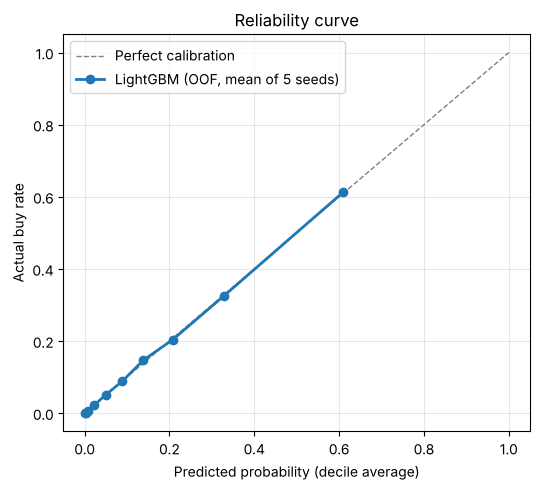

In [12]:
frac_pos, mean_pred = calibration_curve(y, oof_mean, n_bins=10, strategy='quantile')
calib = {'Brier score': brier_score_loss(y, oof_mean),
         'Brier, always predict base rate': brier_score_loss(y, np.full(len(y), BASE_RATE)),
         'Mean predicted probability': oof_mean.mean(), 'Actual buy rate': BASE_RATE,
         'Expected buyers (sum of probabilities)': oof_mean.sum(), 'Actual buyers': int(y.sum())}
display(pd.Series(calib).round(4))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls='--', color='grey', lw=1, label='Perfect calibration')
ax.plot(mean_pred, frac_pos, marker='o', lw=2, label='LightGBM (OOF, mean of 5 seeds)')
ax.set_xlabel('Predicted probability (decile average)'); ax.set_ylabel('Actual buy rate')
ax.set_title('Reliability curve'); ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 11. Fairness by country and age band
Brief §6 requirement 7 asks for fairness. For each group the table shows:
- how well the model ranks within the group (AUC)
- how often the group's customers land in the top 2,500 list (selection rate)
- how many of those selected actually bought (precision)

Age and country are kept as model inputs, and these slices check that the model works comparably for every group.

**How to read it.** A different selection rate is expected when groups genuinely buy at different rates (compare against the group's buy rate). Worry when the AUC or the precision for a group is clearly lower, because that means the model works worse for those customers.

In [13]:
top_k = np.zeros(len(y), bool); top_k[np.argsort(-oof_mean, kind='stable')[:2500]] = True
age_band = (pd.cut(train.age, [0, 25, 35, 45, 55, 200], right=False,
                   labels=['under 25', '25-34', '35-44', '45-54', '55+'])
              .astype(object).where(train.age.notna(), 'unknown').astype(str))

def slice_table(groups):
    rows = []
    for g in sorted(pd.unique(groups)):
        m = (groups == g)
        rows.append({'group': g, 'customers': int(m.sum()), 'buy rate': y[m].mean(),
                     'AUC': roc_auc_score(y[m], oof_mean[m]) if 0 < y[m].sum() < m.sum() else np.nan,
                     'selection rate (top 2,500)': top_k[m].mean(),
                     'precision of selected': y[m & top_k].mean() if (m & top_k).any() else np.nan})
    return pd.DataFrame(rows).set_index('group')

print('By country'); display(slice_table(train.country_code.astype(str).values).round(4))
print('By age band'); display(slice_table(age_band.values).round(4))

By country


,customers,buy rate,AUC,"selection rate (top 2,500)",precision of selected
group,,,,,
DE,12663,0.1405,0.8735,0.0400,0.7648
FR,6470,0.1499,0.8772,0.0382,0.7895
IN,6421,0.1380,0.8824,0.0360,0.7965
UK,12887,0.1499,0.8745,0.0428,0.7554
US,25559,0.1471,0.8723,0.0377,0.7687


By age band


,customers,buy rate,AUC,"selection rate (top 2,500)",precision of selected
group,,,,,
25-34,14907,0.1623,0.8730,0.0500,0.7530
35-44,18026,0.1395,0.8741,0.0345,0.7810
45-54,12452,0.1243,0.8797,0.0273,0.7853
55+,6183,0.1145,0.8704,0.0204,0.7460
under 25,9090,0.1784,0.8689,0.0593,0.7699
unknown,3342,0.1541,0.8654,0.0386,0.7907


## 12. Final model and explanations (SHAP)
For scoring new customers and the `test` set, the model is retrained on **all** 64,000 labelled customers. It is retrained once per seed, using the average tree count from cross-validation, and the 5 seeds' predictions are averaged.

**Why SHAP, not gain.** Gain importance over-credits features with many distinct values: in the 126-feature baseline, pure-noise columns ranked 15th–24th. SHAP splits each individual prediction into per-feature contributions (in log-odds), so the same numbers give global importance and per-customer reasons (W2). LightGBM computes it natively with `pred_contrib=True`.

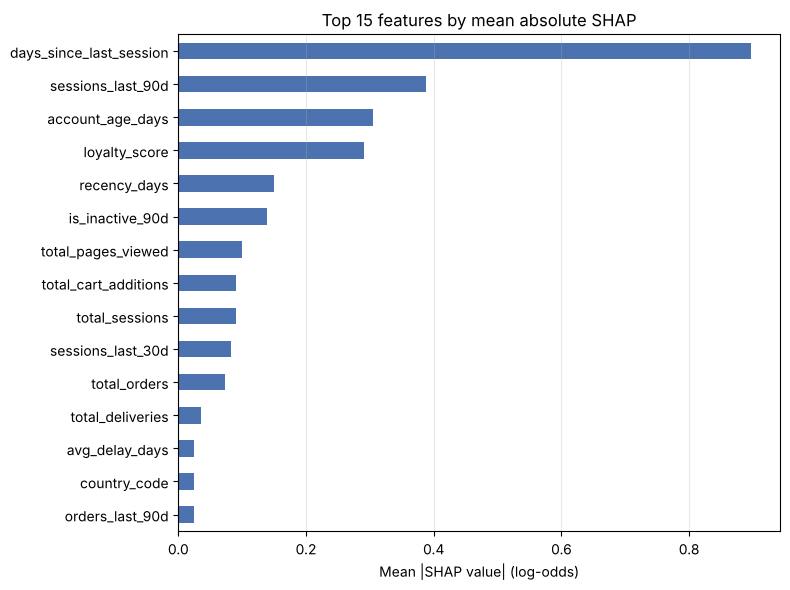

days_since_last_session    0.8974
sessions_last_90d          0.3885
account_age_days           0.3055
loyalty_score              0.2906
recency_days               0.1499
is_inactive_90d            0.1397
total_pages_viewed         0.0993
total_cart_additions       0.0908
total_sessions             0.0900
sessions_last_30d          0.0825
total_orders               0.0734
total_deliveries           0.0355
avg_delay_days             0.0253
country_code               0.0248
orders_last_90d            0.0243
dtype: float64

In [14]:
final_models = []
for s in SEEDS:
    n_trees = int(round(np.mean(seed_iters[s])))
    d_all = lgb.Dataset(X, y, categorical_feature=CATEGORICAL)
    final_models.append(lgb.train({**TUNED_PARAMS, 'seed': s}, d_all, num_boost_round=n_trees))

def predict_final(frame):
    return np.mean([m.predict(frame) for m in final_models], axis=0)

def shap_final(frame):
    # Mean SHAP across the seed models; the last column (bias) is dropped.
    return np.mean([m.predict(frame, pred_contrib=True) for m in final_models], axis=0)[:, :-1]

shap_train = shap_final(X)
importance = pd.Series(np.abs(shap_train).mean(axis=0), index=FEATURES).sort_values(ascending=False)
importance.to_csv(os.path.join(OUT_DIR, 'shap_importance.csv'), header=['mean_abs_shap'])

fig, ax = plt.subplots(figsize=(8, 6))
importance.head(15)[::-1].plot.barh(ax=ax, color='#4C72B0')
ax.set_xlabel('Mean |SHAP value| (log-odds)'); ax.set_title('Top 15 features by mean absolute SHAP')
ax.grid(axis='x', alpha=0.3); plt.tight_layout(); plt.show()
importance.head(15).round(4)

## 13. `score_customer()`: a scoring tool for the agents
If this model becomes the team base, this is the function the agents call. It returns facts about one customer: their probability of buying in the next 30 days, where they rank among all 80,000 customers, and the main reasons. **It gives no offer advice.**
- **Who gets which offer** is the Targeting agent's decision (W2, W3).
- **Whether contact is allowed** is the Compliance agent's: consent, the 30-day rule, open complaints, tier eligibility (W4, W9; `retention_offer_policy.md` §2–3).

A purchase-propensity score says how likely someone is to buy, not whether an offer would change that. Labels such as "persuadable" would need an uplift model, which is out of scope (W10 declined).

For customers in `train`, the final model has seen their outcome, so their score here is in-sample. Evaluation always uses the out-of-fold scores in `outputs/oof_predictions.csv`.

In [15]:
all_scores = pd.Series(predict_final(df[FEATURES]), index=df.customer_id)

def score_customer(customer_id, n_reasons=3):
    # Probability, rank and top SHAP reasons for one customer. No offer advice.
    row = df.loc[df.customer_id == customer_id]
    if row.empty:
        raise KeyError(f'customer {customer_id} not found')
    prob = float(all_scores[customer_id])
    contrib = pd.Series(shap_final(row[FEATURES])[0], index=FEATURES)
    def value(f):
        v = row[f].iloc[0]
        if pd.isna(v):
            return None                                # valid JSON for agent tools (NaN is not)
        return v.item() if hasattr(v, 'item') else v
    reasons = lambda s: [{'feature': f, 'value': value(f), 'shap_log_odds': round(float(s[f]), 3)} for f in s.index]
    return {
        'customer_id': int(customer_id),
        'purchase_probability_30d': round(prob, 4),
        'percentile_among_all_customers': round(float((all_scores < prob).mean() * 100), 1),
        'rank_among_all_customers': int((all_scores > prob).sum() + 1),
        'in_training_data': bool(row.is_test.iloc[0] == 0),
        'reasons_raising_score':  reasons(contrib[contrib > 0].sort_values(ascending=False).head(n_reasons)),
        'reasons_lowering_score': reasons(contrib[contrib < 0].sort_values().head(n_reasons)),
    }

# Demo on two test customers: the highest- and lowest-scored in the test set
test_scores = all_scores.loc[test.customer_id]
for cid in [test_scores.idxmax(), test_scores.idxmin()]:
    print(json.dumps(score_customer(cid), indent=2, default=str))

{
  "customer_id": 65965,
  "purchase_probability_30d": 0.9758,
  "percentile_among_all_customers": 100.0,
  "rank_among_all_customers": 3,
  "in_training_data": false,
  "reasons_raising_score": [
    {
      "feature": "sessions_last_90d",
      "value": 63,
      "shap_log_odds": 1.682
    },
    {
      "feature": "loyalty_score",
      "value": 0.852,
      "shap_log_odds": 1.186
    },
    {
      "feature": "days_since_last_session",
      "value": 0.0,
      "shap_log_odds": 1.166
    }
  ],
  "reasons_lowering_score": [
    {
      "feature": "account_age_days",
      "value": 700.0,
      "shap_log_odds": -0.126
    },
    {
      "feature": "age",
      "value": 51.0,
      "shap_log_odds": -0.012
    },
    {
      "feature": "bounce_rate",
      "value": 0.008130081300813009,
      "shap_log_odds": -0.004
    }
  ]
}
{
  "customer_id": 67880,
  "purchase_probability_30d": 0.0007,
  "percentile_among_all_customers": 0.0,
  "rank_among_all_customers": 79998,
  "in_training_d

## 14. Test-set submission
Brief §8 asks for *"a first test-set submission"* (Week 8) and a *"final test-set submission"* (Week 16), in the format of `sample_submission` (`customer_id, target`). The Guidebook timeline does not mention one, and neither document says whether `target` should be a probability or a 0/1 label. **Confirm with the tutor.**

Both files are written:
- `submission_proba.csv`: the probability.
- `submission_labels.csv`: 1 for the highest-scored customers, as many as the training buy rate implies (14.57%). `sample_submission` holds integer 0s, which suggests labels.

`test` was used only here, never for validation or tuning.

In [16]:
test_final = predict_final(X_test)
sample = q('SELECT customer_id FROM sample_submission')
proba = pd.DataFrame({'customer_id': test.customer_id, 'target': test_final}).set_index('customer_id').loc[sample.customer_id].reset_index()

n_pos = int(round(BASE_RATE * len(proba)))
labels = proba.copy()
labels['target'] = 0
labels.loc[np.argsort(-proba.target.values, kind='stable')[:n_pos], 'target'] = 1

assert len(proba) == 16_000 and proba.customer_id.tolist() == sample.customer_id.tolist()
proba.to_csv(os.path.join(OUT_DIR, 'submission_proba.csv'), index=False)
labels.to_csv(os.path.join(OUT_DIR, 'submission_labels.csv'), index=False)
pd.DataFrame({'customer_id': test.customer_id, 'score': test_final}).to_csv(os.path.join(OUT_DIR, 'test_predictions.csv'), index=False)
print(f'Wrote submissions: mean probability {proba.target.mean():.4f}, labels = 1 for {n_pos:,} of {len(labels):,} customers')

Wrote submissions: mean probability 0.1427, labels = 1 for 2,332 of 16,000 customers


## 15. Saved outputs

In [17]:
metrics = {
    'snapshot': SNAPSHOT, 'n_train': len(train), 'base_rate': BASE_RATE, 'n_features': len(FEATURES), 'features': FEATURES,
    'folds_file': FOLDS_PATH, 'fold_seed': FOLD_SEED, 'model_seeds': SEEDS,
    'tuned_params': TUNED_PARAMS,
    'headline_mean_of_seeds': summary.loc['mean'].to_dict(), 'headline_std_of_seeds': summary.loc['std'].to_dict(),
    'comparison_rankers': results.drop(index='LightGBM, tuned (mean of 5 seeds)').to_dict(orient='index'),
    'budget_k_table': budget_table.to_dict(orient='records'),
    'calibration': calib, 'data_checks': checks,
    'versions': {'lightgbm': lgb.__version__, 'optuna': optuna.__version__, 'sklearn': sklearn.__version__,
                 'pandas': pd.__version__, 'numpy': np.__version__},
}
json.dump(metrics, open(os.path.join(OUT_DIR, 'metrics.json'), 'w'), indent=2, default=float)
conn.close()

for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:28s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e3:8.1f} KB')

best_params.json                  0.2 KB
folds.csv                       503.2 KB
metrics.json                      6.0 KB
oof_predictions.csv            9649.8 KB
shap_importance.csv               1.9 KB
submission_labels.csv           125.7 KB
submission_proba.csv            418.5 KB
test_predictions.csv            418.5 KB


| File | Contents | Who uses it |
|---|---|---|
| `folds.csv` | `customer_id, fold` for the 64,000 train customers | Any model compared against this one: load it, never re-split |
| `oof_predictions.csv` | `customer_id, fold, seed, score` (OOF, 5 seeds) | Comparing any model against the baseline, customer by customer |
| `best_params.json` | Tuned LightGBM settings | Re-running without tuning |
| `metrics.json` | Headline numbers, rankers, budget table, calibration, data checks | Report and slides |
| `shap_importance.csv` | Mean absolute SHAP per feature | W2 explanations, report |
| `test_predictions.csv`, `submission_*.csv` | Test-set scores | Submission (format to be confirmed) |

## 16. Limitations: what not to trust
Per Guidebook §7.3, the A band rewards students who *"can name the parts of their own codebase they would not trust in production"*.

1. **The tuned score is slightly optimistic.** Tuning and evaluation share the same folds (section 7).
2. **The budget-derived *k* is illustrative.** It assumes one offer for everyone and ignores consent, contact limits and per-country budgets.
3. **This is a propensity model, not an uplift model.** It cannot say who would buy *because of* an offer, so it must not be used to claim offers caused purchases.
4. **`loyalty_score` is an undocumented index** from another system. If its definition changed, the model would degrade without warning.
5. **One snapshot, one 30-day window.** The data covers a single October, and November–December are seasonally different (brief §2), so performance on later months is unproven.
6. **Fairness slices** show differences but do not explain them. A group with clearly lower precision would need investigating before deployment.
7. **The best learning rate (0.0103) sits at the bottom of the search range (0.01).** A lower rate might score marginally better, at the cost of more trees and slower training. The top five trials differ by only 0.0001 logloss, so the gain would be small.